# Entrenamiento con LANDMARKS 

Se realizo la combinacion de 2 dataset donde se  conserva solo 13 coincidencias exactas y se  añade cuatro palabras adicionales  `0050` Como esta, `0051` Chao, `0052` Denada y `0053` Lo siento.


- El modelo recibe directamente secuencias de 64 frames con 75 landmarks y coordenadas `x, y, z`.


RUTAS ESTABLECIDAS 

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    IN_COLAB = True
    drive.mount('/content/drive')
    MYDRIVE = Path('/content/drive/MyDrive')
    project_candidates = [
        MYDRIVE / 'FASE 2 IA' / 'Fase 2' / 'Codigo' / 'landmark_recognition',
        MYDRIVE / 'Codigo' / 'landmark_recognition',
        MYDRIVE / 'landmark_recognition',
    ]
    PROJECT_DIR = next((path for path in project_candidates if path.is_dir()), None)
    if PROJECT_DIR is None:
        raise FileNotFoundError('Copia landmark_recognition completa a Google Drive antes de ejecutar.')
    search_roots = [MYDRIVE, MYDRIVE / 'FASE 2 IA' / 'Fase 2', PROJECT_DIR]
    ARCHIVE_PATH = next(
        (root / 'Videos Courtesy.zip' for root in search_roots if (root / 'Videos Courtesy.zip').is_file()),
        None,
    )
    if ARCHIVE_PATH is None:
        raise FileNotFoundError('Sube Videos Courtesy.zip a Mi unidad, FASE 2 IA/Fase 2 o landmark_recognition.')
    LANDMARKS_ARCHIVE_PATH = next(
        (root / 'LANDMARKS.zip' for root in search_roots if (root / 'LANDMARKS.zip').is_file()),
        None,
    )
except ModuleNotFoundError:
    IN_COLAB = False
    cwd = Path.cwd().resolve()
    roots = [cwd, *cwd.parents]
    PROJECT_DIR = next(
        (root if (root / 'courtesy_preprocessing').is_dir() else root / 'landmark_recognition'
         for root in roots
         if (root / 'courtesy_preprocessing').is_dir() or (root / 'landmark_recognition').is_dir()),
        None,
    )
    if PROJECT_DIR is None:
        raise FileNotFoundError('Abre este notebook desde Fase 2, Codigo o landmark_recognition.')
    search_roots = [PROJECT_DIR, *PROJECT_DIR.parents, cwd, *cwd.parents]
    ARCHIVE_PATH = next(
        (root / 'Videos Courtesy.zip' for root in search_roots if (root / 'Videos Courtesy.zip').is_file()),
        None,
    )
    if ARCHIVE_PATH is None:
        raise FileNotFoundError('No se encontr? Videos Courtesy.zip junto al proyecto ni en sus carpetas superiores.')
    LANDMARKS_ARCHIVE_PATH = next(
        (root / 'LANDMARKS.zip' for root in search_roots if (root / 'LANDMARKS.zip').is_file()),
        None,
    )

sys.path.insert(0, str(PROJECT_DIR.parent))
PREPROCESSING_DIR = PROJECT_DIR / 'courtesy_preprocessing'
OUTPUT_DIR = PREPROCESSING_DIR / 'outputs'
CSV_DIR = OUTPUT_DIR / 'landmarks_csv'
COURTESY_DATASET_PATH = PROJECT_DIR / 'data' / 'courtesy_videos.npz'
BASE_DATASET_PATH = PROJECT_DIR / 'data' / 'landmarks_dataset.npz'
COMBINED_DATASET_PATH = PROJECT_DIR / 'data' / 'landmarks_intersection.npz'
CHECKPOINT_PATH = PROJECT_DIR / 'checkpoints' / 'transformer_intersection.pth'
RESULTS_DIR = PROJECT_DIR / 'reports' / 'courtesy_intersection'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print('Proyecto:', PROJECT_DIR)
print('ZIP de videos:', ARCHIVE_PATH, f'({ARCHIVE_PATH.stat().st_size / 1e6:.1f} MB)')

Proyecto: D:\Noveno\Fase 2\Reconocimiento-del-Lenguaje-de-Se-as-Colombiano\FASE 2\Codigo\landmark_recognition
ZIP de videos: D:\Noveno\Fase 2\Videos Courtesy.zip (485.2 MB)


## 1. Reglas de correspondencia

Se realiza la union de palabras que coinciden en ambos datasets y 4 palabras adicionales.

In [2]:
from landmark_recognition.courtesy_preprocessing.class_mapping import (
    DIRECT_VIDEO_LABELS, SEMANTIC_VIDEO_LABELS, DIRECT_CLASSES,
    SEMANTIC_CLASSES, COMBINED_CLASSES, map_video_label,
)
from landmark_recognition.class_labels import CLASS_LABELS

mapping_rows = []
for label, code in DIRECT_VIDEO_LABELS.items():
    mapping_rows.append({'Tipo': 'Coincidencia exacta', 'Etiqueta Courtesy': label, 'Código final': code, 'Nombre': CLASS_LABELS[code]})
for label, code in SEMANTIC_VIDEO_LABELS.items():
    mapping_rows.append({'Tipo': 'Clase semántica independiente', 'Etiqueta Courtesy': label, 'Código final': code, 'Nombre': CLASS_LABELS[code]})
display(pd.DataFrame(mapping_rows).sort_values('Código final').reset_index(drop=True))
assert len(DIRECT_CLASSES) == 13 and len(SEMANTIC_CLASSES) == 4 and len(COMBINED_CLASSES) == 17

,Tipo,Etiqueta Courtesy,Código final,Nombre
0,Coincidencia exacta,gracias,0000,GRACIAS
1,Coincidencia exacta,buenos dias,0001,BUENOS DÍAS
2,Coincidencia exacta,buenas tardes,0002,BUENAS TARDES
3,Coincidencia exacta,buenas noches,0003,BUENAS NOCHES
4,Coincidencia exacta,bien,0024,BIEN
5,Coincidencia exacta,mal,0025,MAL
6,Coincidencia exacta,maso menos,0027,MÁS O MENOS
7,Coincidencia exacta,hola,0030,HOLA
8,Coincidencia exacta,por favor,0032,POR FAVOR
9,Coincidencia exacta,con gusto,0033,CON GUSTO


## 2. Extraer landmarks



In [4]:
MANIFEST_PATH = OUTPUT_DIR / 'extraction_manifest.csv'
if MANIFEST_PATH.is_file():
    manifest = pd.read_csv(MANIFEST_PATH)
    print('Usando manifiesto de extracción existente:', MANIFEST_PATH)
else:
    if ARCHIVE_PATH is None:
        raise FileNotFoundError('No se encontró Videos Courtesy.zip para extraer los landmarks.')
    from landmark_recognition.courtesy_preprocessing.extract_video_landmarks import extract_archive

    MANIFEST_PATH = extract_archive(
        archive_path=ARCHIVE_PATH,
        output_dir=OUTPUT_DIR,
        max_frames=96,
        overwrite=False,
    )
    manifest = pd.read_csv(MANIFEST_PATH)
manifest['status'].value_counts()

Usando manifiesto de extracción existente: D:\Noveno\Fase 2\Reconocimiento-del-Lenguaje-de-Se-as-Colombiano\FASE 2\Codigo\landmark_recognition\courtesy_preprocessing\outputs\extraction_manifest.csv


status
ok    737
Name: count, dtype: int64

Videos seleccionados: 737
Landmarks disponibles: 737
Códigos presentes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(24), np.int64(25), np.int64(27), np.int64(30), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(50), np.int64(51), np.int64(52), np.int64(53)]


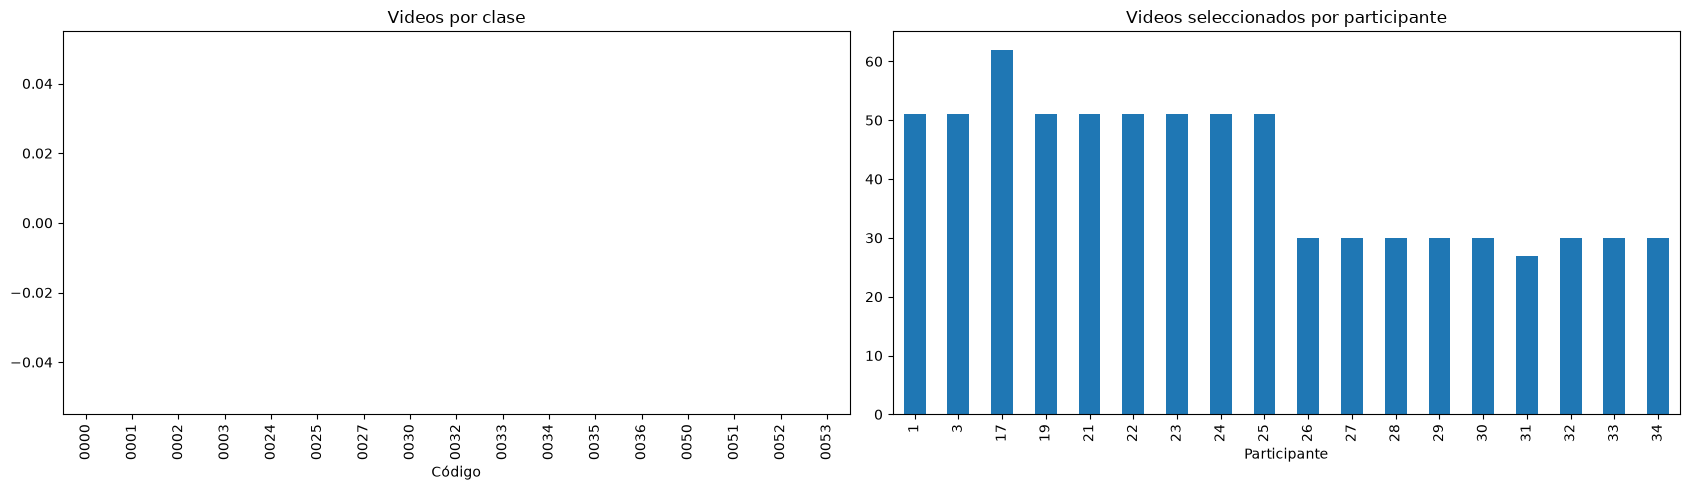

In [5]:
failures = manifest[manifest['status'] == 'error']
if not failures.empty:
    display(failures[['video_member', 'error']].head(20))
    raise RuntimeError(f'{len(failures)} videos fallaron; revisa {MANIFEST_PATH}')

successful = manifest[manifest['status'].isin(['ok', 'skipped_existing'])]
print('Videos seleccionados:', len(manifest))
print('Landmarks disponibles:', len(successful))
print('Códigos presentes:', sorted(manifest['class_name'].unique()))
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
manifest.groupby('class_name').size().reindex(COMBINED_CLASSES, fill_value=0).plot.bar(ax=axes[0], title='Videos por clase')
manifest.groupby('signer').size().sort_index().plot.bar(ax=axes[1], title='Videos seleccionados por participante')
axes[0].set_xlabel('Código'); axes[1].set_xlabel('Participante')
plt.tight_layout(); fig.savefig(RESULTS_DIR / 'extraction_distribution.png', dpi=150); plt.show()

## 3. Preparar el dataset de videos y combinarlo

El dataset Courtesy se convierte a 64 frames. Después se filtra el dataset original a las 13 coincidencias exactas y se agregan las cuatro clases Courtesy aparte. 

In [6]:
from landmark_recognition.preprocessing.prepare_landmark_dataset import prepare_dataset
from landmark_recognition.preprocessing.merge_landmark_datasets import merge_datasets

if not COURTESY_DATASET_PATH.is_file():
    prepare_dataset(CSV_DIR, COURTESY_DATASET_PATH, frame_count=64)
else:
    print('Dataset Courtesy existente:', COURTESY_DATASET_PATH)

if not BASE_DATASET_PATH.is_file():
    if LANDMARKS_ARCHIVE_PATH is None or not LANDMARKS_ARCHIVE_PATH.is_file():
        raise FileNotFoundError(
            f'Falta {BASE_DATASET_PATH} y no se encontró LANDMARKS.zip. '
            'Coloca el NPZ preparado o el ZIP original junto a los datos.'
        )
    prepare_dataset(LANDMARKS_ARCHIVE_PATH, BASE_DATASET_PATH, frame_count=64)

merge_datasets(
    [BASE_DATASET_PATH, COURTESY_DATASET_PATH],
    COMBINED_DATASET_PATH,
    keep_classes=list(COMBINED_CLASSES),
)
with np.load(COMBINED_DATASET_PATH, allow_pickle=False) as data:
    X = data['X'].astype(np.float32)
    y = data['y'].astype(np.int64)
    signers = data['signers'].astype(str)
    sample_ids = data['sample_ids'].astype(str)
    class_names = data['class_names'].astype(str)
assert set(class_names) == set(COMBINED_CLASSES)
print('Secuencias:', X.shape, '| clases:', len(class_names), '| firmantes:', len(np.unique(signers)))

Dataset Courtesy existente: D:\Noveno\Fase 2\Reconocimiento-del-Lenguaje-de-Se-as-Colombiano\FASE 2\Codigo\landmark_recognition\data\courtesy_videos.npz
Saved 997 sequences from 2 datasets, 17 classes to D:\Noveno\Fase 2\Reconocimiento-del-Lenguaje-de-Se-as-Colombiano\FASE 2\Codigo\landmark_recognition\data\landmarks_intersection.npz
Secuencias: (997, 64, 75, 3) | clases: 17 | firmantes: 23


,Código,Seña,LANDMARKS,Courtesy
0,0000,GRACIAS,20,26
1,0001,BUENOS DÍAS,20,54
2,0002,BUENAS TARDES,20,55
3,0003,BUENAS NOCHES,20,57
4,0024,BIEN,20,54
5,0025,MAL,20,51
6,0027,MÁS O MENOS,20,28
7,0030,HOLA,20,53
8,0032,POR FAVOR,20,55
9,0033,CON GUSTO,20,28


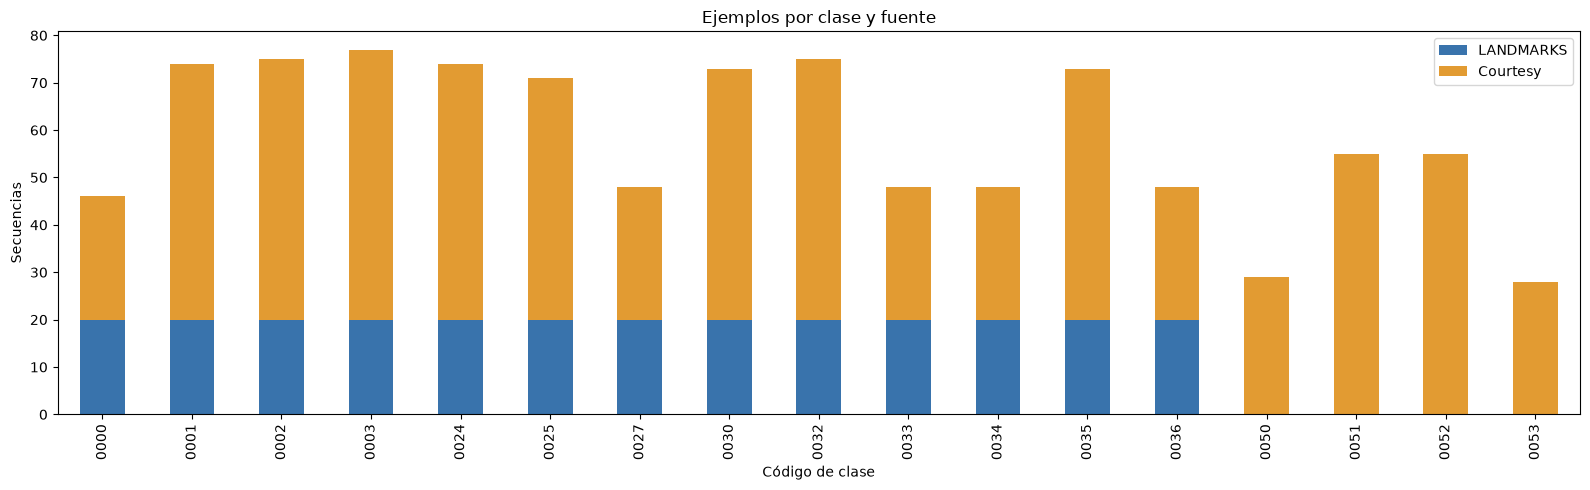

Firmantes con cobertura de las 17 clases: 9


col_0,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
row_0,,,,,,,,,,,,,,,,,
courtesy_videos::0001,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3
courtesy_videos::0003,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3
courtesy_videos::0017,2,3,4,6,3,2,4,2,4,4,4,2,4,5,4,5,4
courtesy_videos::0019,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3
courtesy_videos::0021,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3
courtesy_videos::0022,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3
courtesy_videos::0023,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3
courtesy_videos::0024,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3
courtesy_videos::0025,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3


In [7]:
source_names = np.asarray([sample_id.split('/', 1)[0] for sample_id in sample_ids])
class_index = {name: index for index, name in enumerate(class_names)}
class_counts = pd.DataFrame({
    'Código': class_names,
    'Seña': [CLASS_LABELS[name] for name in class_names],
    'LANDMARKS': [int(np.sum((y == class_index[name]) & (source_names == BASE_DATASET_PATH.stem))) for name in class_names],
    'Courtesy': [int(np.sum((y == class_index[name]) & (source_names == COURTESY_DATASET_PATH.stem))) for name in class_names],
})
display(class_counts)
class_counts.to_csv(RESULTS_DIR / 'class_counts.csv', index=False)
fig, ax = plt.subplots(figsize=(16, 5))
class_counts.set_index('Código')[['LANDMARKS', 'Courtesy']].plot.bar(ax=ax, stacked=True, color=['#3973ac', '#e29b32'])
ax.set_title('Ejemplos por clase y fuente'); ax.set_ylabel('Secuencias'); ax.set_xlabel('Código de clase')
plt.tight_layout(); fig.savefig(RESULTS_DIR / 'class_counts.png', dpi=150); plt.show()

coverage = pd.crosstab(signers, y).reindex(columns=np.arange(len(class_names)), fill_value=0)
print('Firmantes con cobertura de las 17 clases:', int((coverage > 0).all(axis=1).sum()))
display(coverage.iloc[:10])

## 4. Entrenar con separación por participante

El notebook elige dos participantes de Courtesy que tengan ejemplos de las 17 clases: uno para validación y otro para prueba. Ningún video de esos participantes interviene en el ajuste de parámetros. Si no hay al menos tres participantes con las 17 clases, se detiene en vez de presentar una evaluación incompleta como si cubriera todo el vocabulario.

In [8]:
from types import SimpleNamespace
from landmark_recognition.training.train_model import train

courtesy_signers = sorted({signer for signer, sample_id in zip(signers, sample_ids) if sample_id.startswith(COURTESY_DATASET_PATH.stem + '/')})
coverage = pd.crosstab(signers, y).reindex(columns=np.arange(len(class_names)), fill_value=0)
full_coverage_signers = [signer for signer in courtesy_signers if (coverage.loc[signer] > 0).all()]
if len(full_coverage_signers) < 3:
    raise ValueError(
        f'Solo {len(full_coverage_signers)} participantes Courtesy tienen las 17 clases. '
        'Agrega más participantes completos para reservar validación y prueba sin clases ausentes.'
    )
validation_signer, test_signer = full_coverage_signers[-2:]
print('Firmante de validación:', validation_signer)
print('Firmante de prueba:', test_signer)

args = SimpleNamespace(
    dataset=COMBINED_DATASET_PATH,
    architecture='transformer',
    output=CHECKPOINT_PATH,
    epochs=100,
    batch_size=16,
    learning_rate=0.0005,
    validation_signer=validation_signer,
    test_signer=test_signer,
    split_mode='subject',
    no_augmentation=False,
    signer_invariant=True,
    wrist_relative_hands=False,
    include_velocity=False,
    no_mean_shift=False,
    pooling='mean',
    seed=42,
    early_stopping_patience=20,
    early_stopping_min_delta=0.001,
)
train(args)

Firmante de validación: courtesy_videos::0024
Firmante de prueba: courtesy_videos::0025
Signer-invariant mode enabled: wrist-relative hand shapes + velocities + zero-centered normalization.
Split mode=subject; train=895, validation=51, test=51
Participants: train=['courtesy_videos::0001', 'courtesy_videos::0003', 'courtesy_videos::0017', 'courtesy_videos::0019', 'courtesy_videos::0021', 'courtesy_videos::0022', 'courtesy_videos::0023', 'courtesy_videos::0026', 'courtesy_videos::0027', 'courtesy_videos::0028', 'courtesy_videos::0029', 'courtesy_videos::0030', 'courtesy_videos::0031', 'courtesy_videos::0032', 'courtesy_videos::0033', 'courtesy_videos::0034', 'landmarks_dataset::0000', 'landmarks_dataset::0001', 'landmarks_dataset::0002', 'landmarks_dataset::0003', 'landmarks_dataset::0004'], validation=['courtesy_videos::0024'], test=['courtesy_videos::0025']
train class counts: min=22, max=71, missing=[]
validation class counts: min=3, max=3, missing=[]
test class counts: min=3, max=3, 

D:\Noveno\Fase 2\Reconocimiento-del-Lenguaje-de-Se-as-Colombiano\FASE 2\Codigo\landmark_recognition\models.py:62: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=layers)


Epoch 001/100: loss=2.8807, train_accuracy=0.1832, val_loss=2.7173, val_accuracy=0.1569, lr=0.0005
Epoch 002/100: loss=2.5608, train_accuracy=0.2827, val_loss=2.2600, val_accuracy=0.3725, lr=0.0005
Epoch 003/100: loss=2.2270, train_accuracy=0.3955, val_loss=2.0181, val_accuracy=0.3529, lr=0.0005
Epoch 004/100: loss=1.9251, train_accuracy=0.6101, val_loss=1.6612, val_accuracy=0.5882, lr=0.0005
Epoch 005/100: loss=1.6721, train_accuracy=0.6726, val_loss=1.4125, val_accuracy=0.6667, lr=0.0005
Epoch 006/100: loss=1.4821, train_accuracy=0.7765, val_loss=1.4890, val_accuracy=0.5686, lr=0.0005
Epoch 007/100: loss=1.3792, train_accuracy=0.7765, val_loss=1.2114, val_accuracy=0.6471, lr=0.0005
Epoch 008/100: loss=1.2499, train_accuracy=0.8425, val_loss=1.0974, val_accuracy=0.7059, lr=0.0005
Epoch 009/100: loss=1.1425, train_accuracy=0.8883, val_loss=1.0283, val_accuracy=0.7451, lr=0.0005
Epoch 010/100: loss=1.0411, train_accuracy=0.8961, val_loss=0.9617, val_accuracy=0.8039, lr=0.0005
Epoch 011/

## 5. Curvas de aprendizaje

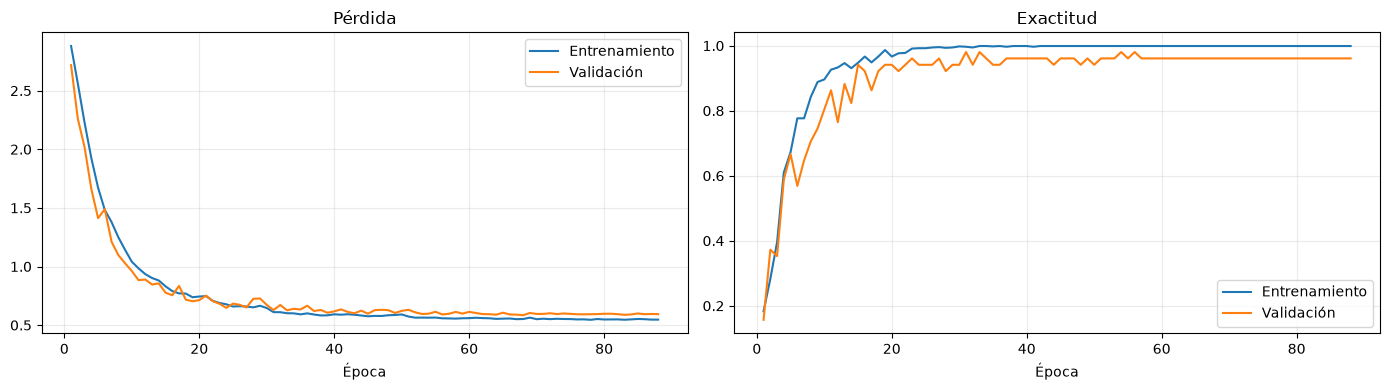

Mejor época: 68
Exactitud validación: 0.9607843137254902
Exactitud prueba: 0.9019607843137255


In [9]:
import torch

checkpoint = torch.load(CHECKPOINT_PATH, map_location='cpu', weights_only=True)
history = checkpoint['history']
epochs = np.arange(1, len(history['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(epochs, history['train_loss'], label='Entrenamiento')
axes[0].plot(epochs, history['validation_loss'], label='Validación')
axes[0].set_title('Pérdida'); axes[0].set_xlabel('Época'); axes[0].legend(); axes[0].grid(alpha=.25)
axes[1].plot(epochs, history['train_accuracy'], label='Entrenamiento')
axes[1].plot(epochs, history['validation_accuracy'], label='Validación')
axes[1].set_title('Exactitud'); axes[1].set_xlabel('Época'); axes[1].legend(); axes[1].grid(alpha=.25)
plt.tight_layout(); fig.savefig(RESULTS_DIR / 'training_curves.png', dpi=150); plt.show()
print('Mejor época:', checkpoint['best_epoch'])
print('Exactitud validación:', checkpoint['validation_accuracy'])
print('Exactitud prueba:', checkpoint['test_accuracy'])

## 6. Matriz de confusión y métricas por seña

Las predicciones guardadas corresponden únicamente al participante reservado para prueba. Se muestran conteos reales/predichos y exactitud por clase; las celdas del conjunto de prueba tienen tres videos Courtesy por seña.

,Código,Seña,Correctas,Prueba,Exactitud
0,0000,GRACIAS,3,3,1.000000
1,0001,BUENOS DÍAS,3,3,1.000000
2,0002,BUENAS TARDES,2,3,0.666667
3,0003,BUENAS NOCHES,3,3,1.000000
4,0024,BIEN,3,3,1.000000
5,0025,MAL,3,3,1.000000
6,0027,MÁS O MENOS,1,3,0.333333
7,0030,HOLA,3,3,1.000000
8,0032,POR FAVOR,3,3,1.000000
9,0033,CON GUSTO,3,3,1.000000


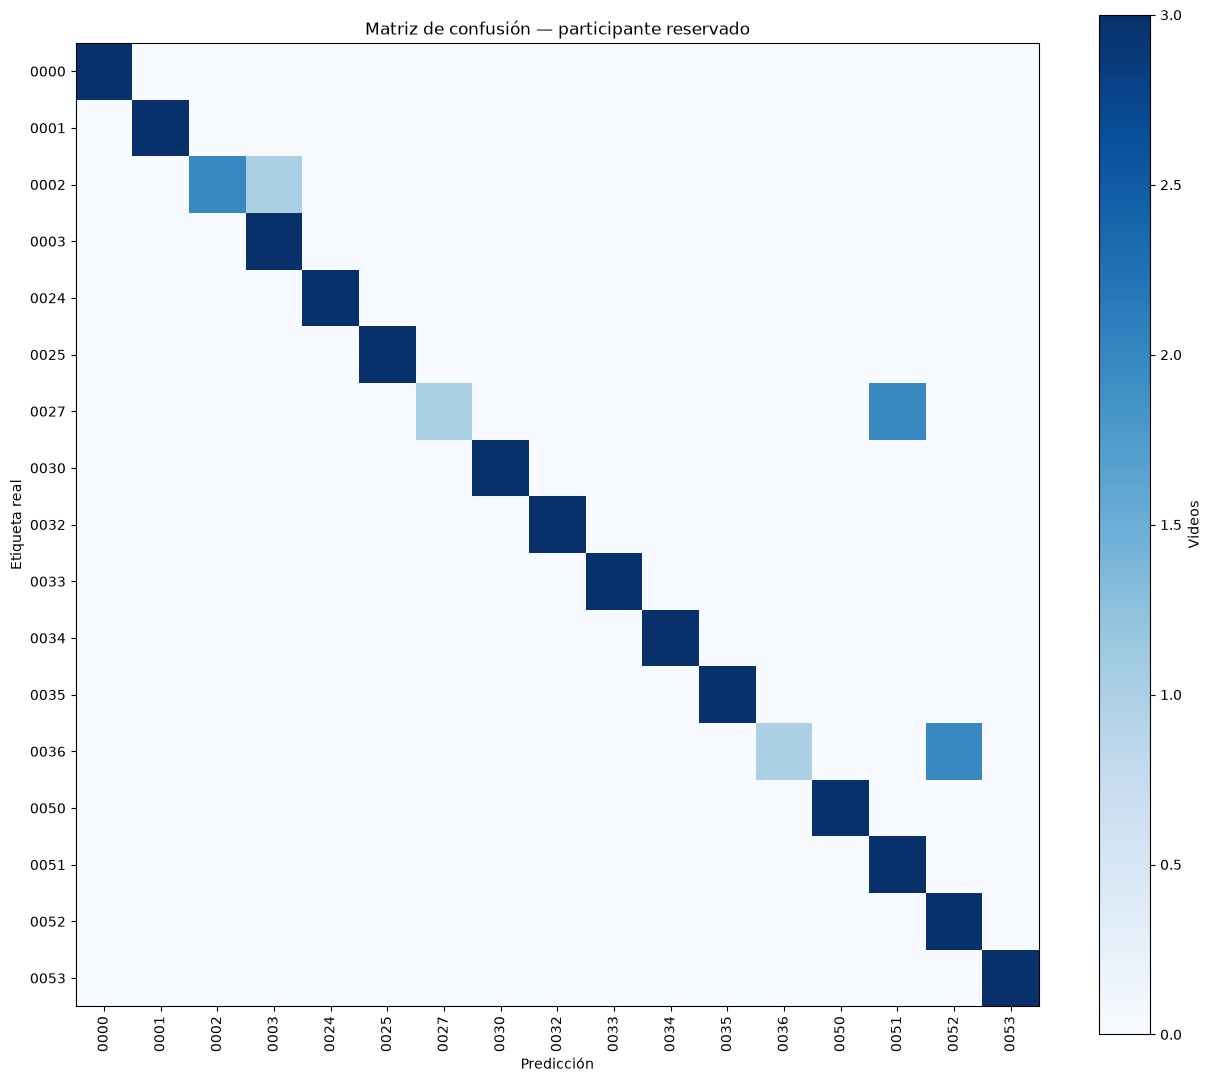

Exactitud del participante de prueba: 0.902


In [10]:
targets = np.asarray(checkpoint['test_targets'], dtype=int)
predictions = np.asarray(checkpoint['test_predictions'], dtype=int)
if not len(targets):
    raise ValueError('El checkpoint no contiene predicciones de prueba.')
confusion = np.zeros((len(class_names), len(class_names)), dtype=int)
np.add.at(confusion, (targets, predictions), 1)
per_class = []
for index, code in enumerate(class_names):
    total = int(confusion[index].sum())
    per_class.append({'Código': code, 'Seña': CLASS_LABELS[code], 'Correctas': int(confusion[index, index]), 'Prueba': total, 'Exactitud': confusion[index, index] / total if total else np.nan})
per_class_df = pd.DataFrame(per_class)
display(per_class_df)
per_class_df.to_csv(RESULTS_DIR / 'test_metrics_per_class.csv', index=False)
fig, ax = plt.subplots(figsize=(13, 11))
image = ax.imshow(confusion, cmap='Blues')
ax.set_title('Matriz de confusión — participante reservado')
ax.set_xlabel('Predicción'); ax.set_ylabel('Etiqueta real')
ax.set_xticks(np.arange(len(class_names)), class_names, rotation=90)
ax.set_yticks(np.arange(len(class_names)), class_names)
fig.colorbar(image, ax=ax, label='Videos')
plt.tight_layout(); fig.savefig(RESULTS_DIR / 'confusion_matrix.png', dpi=150); plt.show()
print(f'Exactitud del participante de prueba: {(targets == predictions).mean():.3f}')

In [20]:
from sklearn.metrics import classification_report

# Calcular métricas
report = classification_report(
    targets,
    predictions,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

# Construir tabla por clase
per_class = []

for code in class_names:
    row = report[code]

    per_class.append({
        'Código': code,
        'Seña': CLASS_LABELS[code],
        'Precision (%)': row['precision'] * 100,
        'Recall (%)': row['recall'] * 100,
        'F1-score (%)': row['f1-score'] * 100,
        'Videos': int(row['support'])
    })

per_class_df = pd.DataFrame(per_class)

# Mostrar tabla
display(
    per_class_df.style
    .format({
        'Precision (%)': '{:.2f}',
        'Recall (%)': '{:.2f}',
        'F1-score (%)': '{:.2f}',
        'Videos': '{:.0f}'
    })
    .background_gradient(
        subset=['F1-score (%)'],
        cmap='Blues'
    )
    .hide(axis='index')
)

# Guardar
per_class_df.to_csv(
    RESULTS_DIR / 'test_metrics_per_class.csv',
    index=False
)

# Métricas globales
print(f"\nAccuracy: {report['accuracy']*100:.2f}%")
print(f"F1 Macro: {report['macro avg']['f1-score']*100:.2f}%")
print(f"F1 Weighted: {report['weighted avg']['f1-score']*100:.2f}%")

Código,Seña,Precision (%),Recall (%),F1-score (%),Videos
0000,GRACIAS,100.00,100.00,100.00,3
0001,BUENOS DÍAS,100.00,100.00,100.00,3
0002,BUENAS TARDES,100.00,66.67,80.00,3
0003,BUENAS NOCHES,75.00,100.00,85.71,3
0024,BIEN,100.00,100.00,100.00,3
0025,MAL,100.00,100.00,100.00,3
0027,MÁS O MENOS,100.00,33.33,50.00,3
0030,HOLA,100.00,100.00,100.00,3
0032,POR FAVOR,100.00,100.00,100.00,3
0033,CON GUSTO,100.00,100.00,100.00,3



Accuracy: 90.20%
F1 Macro: 89.16%
F1 Weighted: 89.16%
